<a href="https://colab.research.google.com/github/lachlanwalsh87/Portfolio-Optimisation-Project/blob/main/Portfolio_Optimisation_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

[*********************100%***********************]  5 of 5 completed


                Return  Volatility  Sharpe
Equal weight    0.2817      0.2134  1.1325
Min volatility  0.1416      0.1397  0.7274
Max Sharpe      0.3582      0.2404  1.3237
      Equal weight  Min volatility  Max Sharpe
AAPL           0.2          0.0047      0.0000
MSFT           0.2          0.1547      0.0000
NVDA           0.2          0.0000      0.3687
JPM            0.2          0.1790      0.3355
KO             0.2          0.6616      0.2959


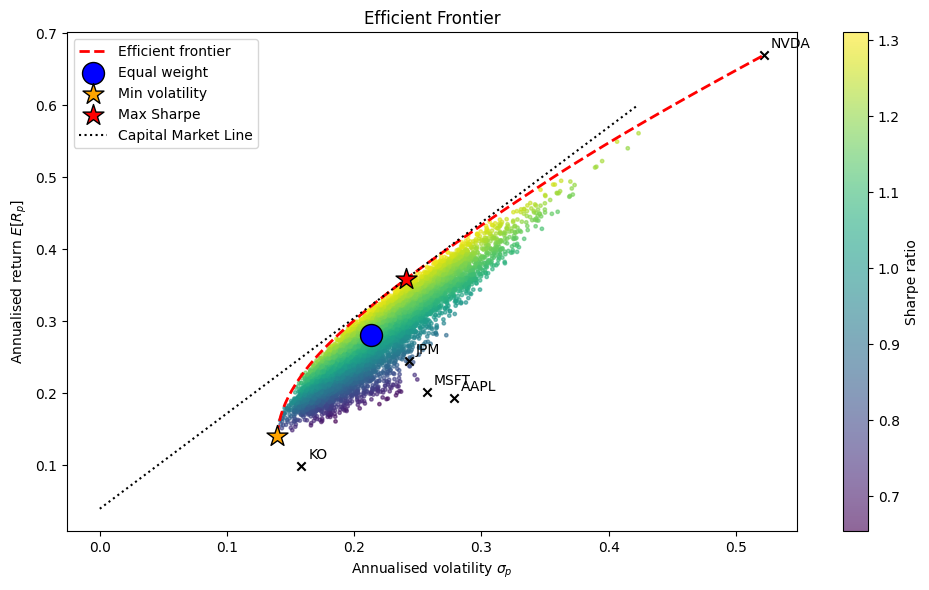

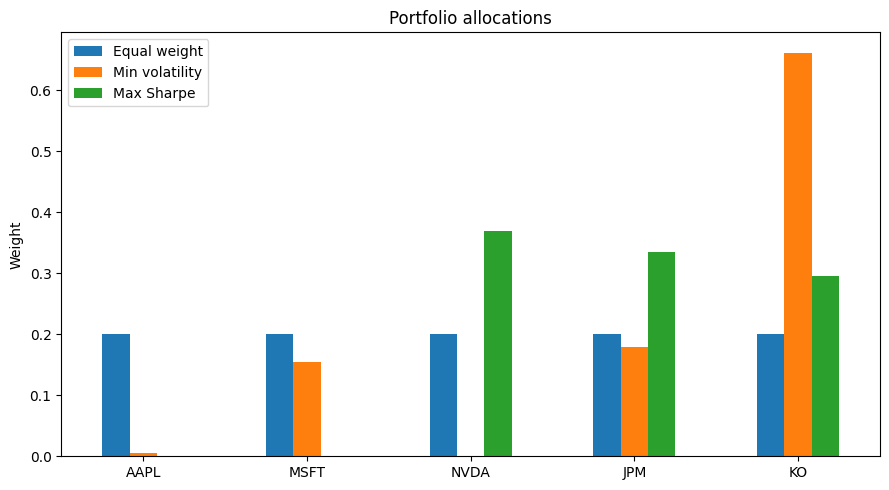

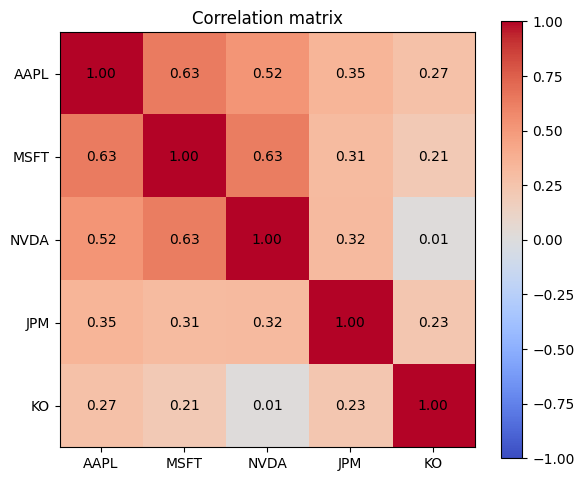

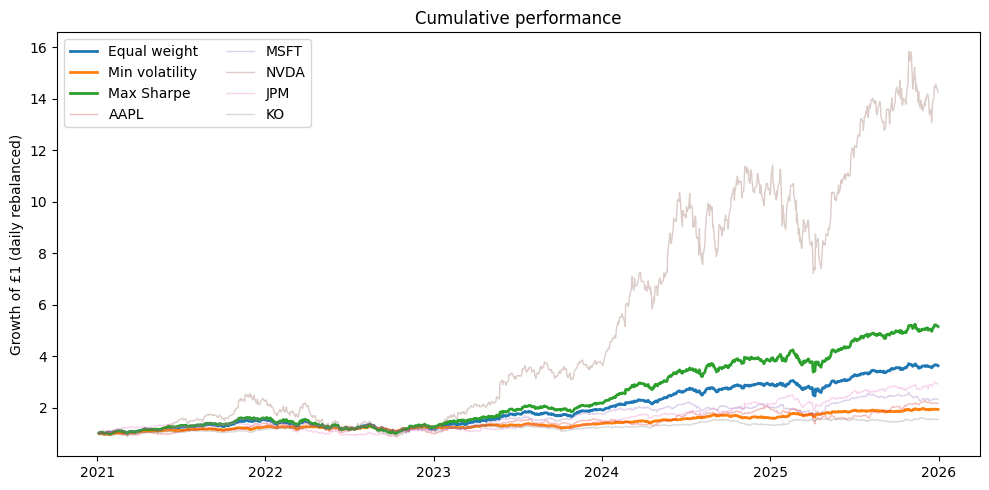

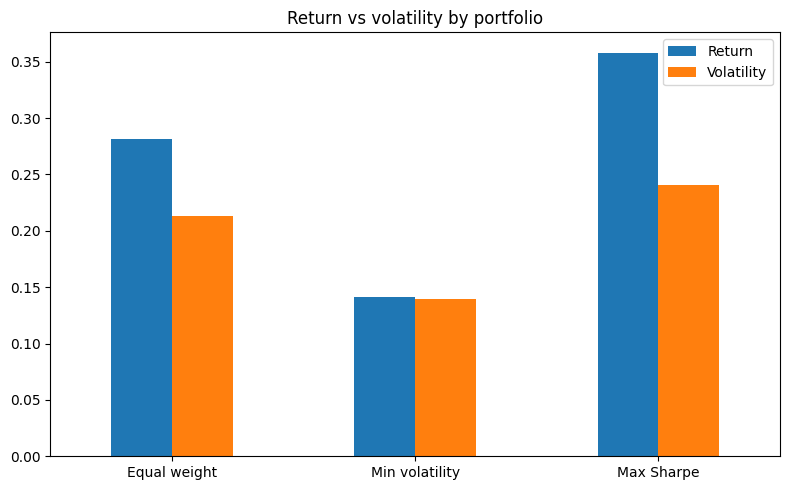

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf
from scipy.optimize import minimize

np.random.seed(42)

# ---------- DATA ----------
tickers = ["AAPL", "MSFT", "NVDA", "JPM", "KO"]
data = yf.download(tickers, start="2021-01-01", end="2026-01-01", auto_adjust=True)
prices = data["Close"][tickers]          # FIX: force column order to match `tickers`
returns = prices.pct_change().dropna()

n = len(tickers)
mu = returns.mean().values * 252         # annualised mean returns
cov = returns.cov().values * 252         # annualised covariance matrix
rf = 0.04

# ---------- HELPERS ----------
def perf(w):
    ret = w @ mu
    vol = np.sqrt(w @ cov @ w)
    return ret, vol, (ret - rf) / vol

def neg_sharpe(w):
    return -perf(w)[2]

def vol_fn(w):
    return perf(w)[1]

bounds = [(0, 1)] * n
sum_to_one = {"type": "eq", "fun": lambda w: np.sum(w) - 1}
w0 = np.ones(n) / n

# ---------- OPTIMISATION ----------
w_eq = w0
w_minvol = minimize(vol_fn, w0, method="SLSQP", bounds=bounds, constraints=[sum_to_one]).x
w_maxsharpe = minimize(neg_sharpe, w0, method="SLSQP", bounds=bounds, constraints=[sum_to_one]).x

portfolios = {
    "Equal weight": w_eq,
    "Min volatility": w_minvol,
    "Max Sharpe": w_maxsharpe,
}

summary = pd.DataFrame(
    {name: perf(w) for name, w in portfolios.items()},
    index=["Return", "Volatility", "Sharpe"],
).T
print(summary.round(4))
print(pd.DataFrame(portfolios, index=tickers).round(4))

# ---------- MONTE CARLO ----------
N = 10000
mc_ret, mc_vol, mc_sharpe = np.zeros(N), np.zeros(N), np.zeros(N)
for i in range(N):
    w = np.random.random(n)
    w /= w.sum()
    mc_ret[i], mc_vol[i], mc_sharpe[i] = perf(w)

# ---------- EFFICIENT FRONTIER ----------
target_rets = np.linspace(perf(w_minvol)[0], mu.max(), 60)
frontier_vol = []
for t in target_rets:
    cons = [sum_to_one, {"type": "eq", "fun": lambda w, t=t: w @ mu - t}]
    res = minimize(vol_fn, w0, method="SLSQP", bounds=bounds, constraints=cons)
    frontier_vol.append(res.fun)

# ---------- PLOT 1: EFFICIENT FRONTIER ----------
fig, ax = plt.subplots(figsize=(10, 6))
sc = ax.scatter(mc_vol, mc_ret, c=mc_sharpe, cmap="viridis", s=6, alpha=0.6)
plt.colorbar(sc, label="Sharpe ratio")
ax.plot(frontier_vol, target_rets, "r--", lw=2, label="Efficient frontier")

markers = {"Equal weight": ("o", "blue"), "Min volatility": ("*", "orange"), "Max Sharpe": ("*", "red")}
for name, w in portfolios.items():
    r, v, _ = perf(w)
    m, c = markers[name]
    ax.scatter(v, r, marker=m, color=c, s=250, edgecolor="black", zorder=5, label=name)

# individual assets
for i, t in enumerate(tickers):
    ax.scatter(np.sqrt(cov[i, i]), mu[i], marker="x", color="black")
    ax.annotate(t, (np.sqrt(cov[i, i]), mu[i]), xytext=(5, 5), textcoords="offset points")

# Capital Market Line
_, v_s, _ = perf(w_maxsharpe)
r_s = perf(w_maxsharpe)[0]
x = np.linspace(0, mc_vol.max(), 50)
ax.plot(x, rf + (r_s - rf) / v_s * x, "k:", label="Capital Market Line")

ax.set_xlabel("Annualised volatility $\\sigma_p$")
ax.set_ylabel("Annualised return $E[R_p]$")
ax.set_title("Efficient Frontier")
ax.legend()
plt.tight_layout()

# ---------- PLOT 2: WEIGHTS ----------
weights_df = pd.DataFrame(portfolios, index=tickers)
weights_df.plot(kind="bar", figsize=(9, 5))
plt.ylabel("Weight")
plt.title("Portfolio allocations")
plt.xticks(rotation=0)
plt.tight_layout()

# ---------- PLOT 3: CORRELATION HEATMAP ----------
corr = returns.corr().values
fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(n)); ax.set_xticklabels(tickers)
ax.set_yticks(range(n)); ax.set_yticklabels(tickers)
for i in range(n):
    for j in range(n):
        ax.text(j, i, f"{corr[i, j]:.2f}", ha="center", va="center")
plt.colorbar(im)
ax.set_title("Correlation matrix")
plt.tight_layout()

# ---------- PLOT 4: CUMULATIVE PERFORMANCE ----------
fig, ax = plt.subplots(figsize=(10, 5))
for name, w in portfolios.items():
    ax.plot((1 + returns @ w).cumprod(), label=name, lw=2)
for t in tickers:
    ax.plot((1 + returns[t]).cumprod(), alpha=0.3, lw=1, label=t)
ax.set_ylabel("Growth of £1 (daily rebalanced)")
ax.set_title("Cumulative performance")
ax.legend(ncol=2)
plt.tight_layout()

# ---------- PLOT 5: RISK / RETURN TABLE ----------
summary[["Return", "Volatility"]].plot(kind="bar", figsize=(8, 5))
plt.title("Return vs volatility by portfolio")
plt.xticks(rotation=0)
plt.tight_layout()

plt.show()